In [1]:
import pandas as pd


In [2]:
df = pd.read_excel('../data/mutaciones_rare_diseases/rare_disease_variations2 (1).xlsx')
print(df.shape)
print(list(df.columns))

(3605, 8)
['Gene(s)', 'GeneSymbol', 'Disease', 'Condition(s)', 'Protein change', 'Molecular consequence', 'VariationID', 'Germline classification']


In [3]:
df = df[['GeneSymbol','Condition(s)','Protein change','Molecular consequence','VariationID','Germline classification']]
print(df.shape)
columnas = list(df.columns)
columnas

(3605, 6)


['GeneSymbol',
 'Condition(s)',
 'Protein change',
 'Molecular consequence',
 'VariationID',
 'Germline classification']

In [4]:
# Eliminar las filas que contienen 'BMPR1B' en la columna 'Condition(s)'
df = df[~df['Condition(s)'].str.contains('BMPR1B', na=False)]
df.loc[df['Condition(s)'].str.contains('BMPR1B')]
df

,GeneSymbol,Condition(s),Protein change,Molecular consequence,VariationID,Germline classification
0,ACVR1,Progressive myositis ossificans,R258G,missense variant,216885,Likely pathogenic
1,ACVR1,Progressive myositis ossificans,R258G,missense variant,216885,Likely pathogenic
2,ACVR1,Progressive myositis ossificans,L196P,missense variant,208843,Pathogenic
3,ACVR1,Progressive myositis ossificans,L196P,missense variant,208843,Pathogenic
4,ACVR1,Progressive myositis ossificans,R202I,missense variant,29597,Pathogenic
...,...,...,...,...,...,...
3600,TGFBR2,Loeys-Dietz syndrome 2,L317P,missense variant,12505,Pathogenic
3601,TGFBR2,Loeys-Dietz syndrome 2,L344P,missense variant,12505,Pathogenic
3602,TGFBR2,Loeys-Dietz syndrome 2,L369P,missense variant,12505,Pathogenic
3603,TGFBR2,"Colorectal cancer, hereditary nonpolyposis, ty...",A535fs,frameshift variant,12501,Pathogenic


In [5]:
df = df.drop_duplicates(columnas)
df.shape

(1900, 6)

In [6]:
df['Protein change'].nunique()

1564

In [7]:
df.loc[df['GeneSymbol'].str.contains('BMPR1A')]

,GeneSymbol,Condition(s),Protein change,Molecular consequence,VariationID,Germline classification
487,BMPR1A,Juvenile polyposis syndrome,Y192fs,frameshift variant|non-coding transcript variant,3236417,Likely pathogenic
490,BMPR1A,Juvenile polyposis syndrome,Y278fs,frameshift variant|non-coding transcript variant,3236417,Likely pathogenic
493,BMPR1A,Juvenile polyposis syndrome,Y304fs,frameshift variant|non-coding transcript variant,3236417,Likely pathogenic
496,BMPR1A,Juvenile polyposis syndrome,Y306fs,frameshift variant|non-coding transcript variant,3236417,Likely pathogenic
499,BMPR1A,Juvenile polyposis syndrome,Y322fs,frameshift variant|non-coding transcript variant,3236417,Likely pathogenic
...,...,...,...,...,...,...
1834,BMPR1A,"Polyposis syndrome, hereditary mixed, 2",C124R,missense variant,8234,Pathogenic/Likely pathogenic
1837,BMPR1A,Hereditary cancer-predisposing syndrome,C124R,missense variant,8234,Pathogenic/Likely pathogenic
1840,BMPR1A,Hereditary cancer-predisposing syndrome,A338D,missense variant,8233,Likely pathogenic
1843,BMPR1A,Hereditary cancer-predisposing syndrome,W271*,nonsense,8231,Pathogenic


In [8]:
df.loc[df['GeneSymbol'].str.contains('TGFBR2')]

,GeneSymbol,Condition(s),Protein change,Molecular consequence,VariationID,Germline classification
3172,TGFBR2,Loeys-Dietz syndrome 2,A241D,missense variant,3235255,Likely pathogenic
3173,TGFBR2,Loeys-Dietz syndrome 2,A411D,missense variant,3235255,Likely pathogenic
3174,TGFBR2,Loeys-Dietz syndrome 2,A436D,missense variant,3235255,Likely pathogenic
3175,TGFBR2,Loeys-Dietz syndrome 2,A496D,missense variant,3235255,Likely pathogenic
3176,TGFBR2,Loeys-Dietz syndrome 2,A530D,missense variant,3235255,Likely pathogenic
...,...,...,...,...,...,...
3600,TGFBR2,Loeys-Dietz syndrome 2,L317P,missense variant,12505,Pathogenic
3601,TGFBR2,Loeys-Dietz syndrome 2,L344P,missense variant,12505,Pathogenic
3602,TGFBR2,Loeys-Dietz syndrome 2,L369P,missense variant,12505,Pathogenic
3603,TGFBR2,"Colorectal cancer, hereditary nonpolyposis, ty...",A535fs,frameshift variant,12501,Pathogenic


In [9]:
list(df['Condition(s)'].unique())

['Progressive myositis ossificans',
 'Heterotaxy, visceral, 4, autosomal',
 'Hereditary hemorrhagic telangiectasia',
 'Telangiectasia, hereditary hemorrhagic, type 2',
 'Pulmonary arterial hypertension, 1',
 'Telangiectasia, hereditary hemorrhagic, type 1',
 'Pulmonary arterial hypertension related to hereditary hemorrhagic telangiectasia',
 'Pulmonary hypertension, primary, 1',
 'Pulmonary arterial hypertension',
 'Juvenile polyposis syndrome',
 'Hereditary cancer-predisposing syndrome',
 'Polyposis syndrome, hereditary mixed, 2',
 'Generalized juvenile polyposis/juvenile polyposis coli',
 'Acromesomelic dysplasia 3',
 'Type A2 brachydactyly',
 'Acromesomelic dysplasia 2C, Hunter-Thompson type',
 'Brachydactyly type A1D',
 'Acromesomelic dysplasia 2B',
 'Primary pulmonary hypertension',
 'Pulmonary venoocclusive disease 1',
 'Pulmonary arterial hypertension associated with congenital heart disease',
 'Pulmonary hypertension, primary, dexfenfluramine-associated',
 'Pulmonary hypertensi

In [10]:
# Diccionario con los acrónimos que quieres agregar
acronimos = {
 'Progressive myositis ossificans' : 'FOP',
 'Heterotaxy, visceral, 4, autosomal' : 'HTX4',
 'Hereditary hemorrhagic telangiectasia' : 'HHT' ,
 'Telangiectasia, hereditary hemorrhagic, type 2' : 'HHT2',
 'Pulmonary arterial hypertension, 1' : 'PAH1',
 'Telangiectasia, hereditary hemorrhagic, type 1' : 'HHT1',
 'Pulmonary arterial hypertension related to hereditary hemorrhagic telangiectasia' : 'PAH-HHT',
 'Pulmonary hypertension, primary, 1' : 'PPH1',
 'Pulmonary arterial hypertension' : 'PAH',
 'Juvenile polyposis syndrome' : 'JPS',
 'Hereditary cancer-predisposing syndrome' : 'HCPS',
 'Polyposis syndrome, hereditary mixed, 2' : 'HMPS2',
 'Generalized juvenile polyposis/juvenile polyposis coli' : 'JPSC',
 'Acromesomelic dysplasia 3' : 'AMD3', 
 'Type A2 brachydactyly' : 'BDA2',
 'Acromesomelic dysplasia 2C, Hunter-Thompson type' : 'AMD2C-HTT',
 'Brachydactyly type A1D' : 'BDA1D',
 'Acromesomelic dysplasia 2B' : 'AMD2B',
 'Primary pulmonary hypertension' : 'PPH',
 'Pulmonary venoocclusive disease 1' : 'PVOD1',
 'Pulmonary arterial hypertension associated with congenital heart disease' : 'PAH-CHD',
 'Pulmonary hypertension, primary, dexfenfluramine-associated' : 'PPH1-dexfenfluramine',
 'Pulmonary hypertension, primary, 1, with hereditary hemorrhagic telangiectasia' : 'PPH1-HHT',
 'Loeys-Dietz syndrome 1' : 'LDS1',
 'Loeys-Dietz syndrome': 'LDS',
 'Multiple self-healing squamous epithelioma' : 'MSSE',
 'Marfan syndrome' : 'MFS',
 'Loeys-Dietz syndrome 2' : 'LDS2',
 'Colorectal cancer, hereditary nonpolyposis, type 6' : 'HNPCC6'
}



# Crear la columna de acrónimos utilizando el mapeo
df['Condition'] = df['Condition(s)'].map(acronimos)

df






/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_8354/3916748658.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Condition'] = df['Condition(s)'].map(acronimos)


,GeneSymbol,Condition(s),Protein change,Molecular consequence,VariationID,Germline classification,Condition
0,ACVR1,Progressive myositis ossificans,R258G,missense variant,216885,Likely pathogenic,FOP
2,ACVR1,Progressive myositis ossificans,L196P,missense variant,208843,Pathogenic,FOP
4,ACVR1,Progressive myositis ossificans,R202I,missense variant,29597,Pathogenic,FOP
6,ACVR1,Progressive myositis ossificans,R375P,missense variant,29596,Pathogenic,FOP
8,ACVR1,Progressive myositis ossificans,G328E,missense variant,29595,Pathogenic/Likely pathogenic,FOP
...,...,...,...,...,...,...,...
3600,TGFBR2,Loeys-Dietz syndrome 2,L317P,missense variant,12505,Pathogenic,LDS2
3601,TGFBR2,Loeys-Dietz syndrome 2,L344P,missense variant,12505,Pathogenic,LDS2
3602,TGFBR2,Loeys-Dietz syndrome 2,L369P,missense variant,12505,Pathogenic,LDS2
3603,TGFBR2,"Colorectal cancer, hereditary nonpolyposis, ty...",A535fs,frameshift variant,12501,Pathogenic,HNPCC6


In [11]:
# Cambiar el nombre de las filas en la columna 'Molecular consequence'
df.loc[df['Molecular consequence'] == 'frameshift variant|non-coding transcript variant', 'Molecular consequence'] = 'frameshift variant'
df.loc[df['Molecular consequence'] == 'missense variant|intron variant', 'Molecular consequence'] = 'missense variant'
df.loc[df['Molecular consequence'] == 'nonsense|non-coding transcript variant', 'Molecular consequence'] = 'nonsense'
df.loc[df['Molecular consequence'] == 'frameshift variant|non-coding transcript variant|intron variant', 'Molecular consequence'] = 'frameshift variant'
df.loc[df['Molecular consequence'] == 'missense variant|non-coding transcript variant', 'Molecular consequence'] = 'missense variant'
df.loc[df['Molecular consequence'] == 'nonsense|non-coding transcript variant|intron variant', 'Molecular consequence'] = 'nonsense'
df.loc[df['Molecular consequence'] == 'missense variant|non-coding transcript variant|intron variant', 'Molecular consequence'] = 'missense variant'
df.loc[df['Molecular consequence'] == 'nonsense|intron variant', 'Molecular consequence'] = 'nonsense'
df.loc[df['Molecular consequence'] == 'frameshift variant|intron variant', 'Molecular consequence'] = 'frameshift variant'
df.loc[df['Molecular consequence'] == 'missense variant|initiator_codon_variant', 'Molecular consequence'] = 'missense variant'
df.loc[df['Molecular consequence'] == 'splice donor variant|missense variant', 'Molecular consequence'] = 'missense variant'
df.loc[df['Molecular consequence'] == 'frameshift variant|initiator_codon_variant|5 prime UTR variant|non-coding transcript variant|intron variant', 'Molecular consequence'] = 'frameshift variant'
df.loc[df['Molecular consequence'] == 'frameshift variant|5 prime UTR variant|non-coding transcript variant', 'Molecular consequence'] = 'frameshift variant'
df.loc[df['Molecular consequence'] == 'nonsense|5 prime UTR variant|non-coding transcript variant|intron variant', 'Molecular consequence'] = 'nonsense'
df.loc[df['Molecular consequence'] == 'intron variant|missense variant', 'Molecular consequence'] = 'missense variant'
df.loc[df['Molecular consequence'] == 'intron variant|frameshift variant', 'Molecular consequence'] = 'frameshift variant'
df.loc[df['Molecular consequence'] == 'inframe_deletion|initiator_codon_variant', 'Molecular consequence'] = 'inframe_deletion'
df.loc[df['Molecular consequence'] == 'frameshift variant|5 prime UTR variant|non-coding transcript variant|intron variant', 'Molecular consequence'] = 'frameshift variant'
df.loc[df['Molecular consequence'] == 'missense variant|splice donor variant', 'Molecular consequence'] = 'missense variant'

In [12]:
df.loc[df['Condition(s)'].str.contains('TGFBR2')]

,GeneSymbol,Condition(s),Protein change,Molecular consequence,VariationID,Germline classification,Condition


In [13]:
df

,GeneSymbol,Condition(s),Protein change,Molecular consequence,VariationID,Germline classification,Condition
0,ACVR1,Progressive myositis ossificans,R258G,missense variant,216885,Likely pathogenic,FOP
2,ACVR1,Progressive myositis ossificans,L196P,missense variant,208843,Pathogenic,FOP
4,ACVR1,Progressive myositis ossificans,R202I,missense variant,29597,Pathogenic,FOP
6,ACVR1,Progressive myositis ossificans,R375P,missense variant,29596,Pathogenic,FOP
8,ACVR1,Progressive myositis ossificans,G328E,missense variant,29595,Pathogenic/Likely pathogenic,FOP
...,...,...,...,...,...,...,...
3600,TGFBR2,Loeys-Dietz syndrome 2,L317P,missense variant,12505,Pathogenic,LDS2
3601,TGFBR2,Loeys-Dietz syndrome 2,L344P,missense variant,12505,Pathogenic,LDS2
3602,TGFBR2,Loeys-Dietz syndrome 2,L369P,missense variant,12505,Pathogenic,LDS2
3603,TGFBR2,"Colorectal cancer, hereditary nonpolyposis, ty...",A535fs,frameshift variant,12501,Pathogenic,HNPCC6


In [14]:
import altair as alt

# Crear el gráfico
chart = alt.Chart(df).transform_aggregate(
    unique_aa_mutation='distinct(Protein change)',
    groupby=['GeneSymbol', 'Condition', 'Protein change']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('Condition', sort='-y', title='Enfermedad rara', axis=alt.Axis(
        labelAngle=-40, labelFontSize=10)
    ),
    color=alt.Color('GeneSymbol', scale=alt.Scale(scheme='category20'), title='Genes')
).properties(
    title="Número de mutaciones en enfermedades raras",
    width=800,  # Aumentar el ancho del gráfico
    height=400  # Mantener el alto del gráfico
).configure_legend(
    orient='right',  # Colocar la leyenda a la derecha
    labelLimit=200,  # Ajustar el límite de longitud de las etiquetas de la leyenda
    titleFontSize=12,  # Tamaño de fuente del título de la leyenda
    labelFontSize=10,  # Tamaño de fuente de las etiquetas de la leyenda
)

# Ajustar la vista del gráfico
chart = chart.configure_view(
    stroke=None,  # Eliminar el borde del gráfico
    clip=False,  # Aumentar el padding para dar más espacio
    discreteWidth=1
)

chart


alt.Chart(...)

In [15]:
# Crear una lista única de condiciones de enfermedades raras en el DataFrame
lista_rd = df['Condition'].unique()

# Crear un diccionario para almacenar un DataFrame por cada condición de enfermedad rara
dict_rd = {}

# Iterar sobre cada condición en lista_rd
for tipo in lista_rd:
    # Filtrar el DataFrame original para obtener solo las filas correspondientes a la condición actual
    df_disease = df[df['Condition'] == tipo]
    
    # Asignar el DataFrame filtrado al diccionario con la clave correspondiente a la condición
    dict_rd[tipo] = df_disease

# Iterar sobre el diccionario ordenado por el número de mutaciones únicas en 'Protein change', en orden descendente
for i, (Disease, data) in enumerate(sorted(dict_rd.items(), key=lambda x: len(x[1]['Protein change'].unique()), reverse=True)):
    print(f"{i+1}. Número de mutaciones en enfermedades raras {Disease}: {len(data['Protein change'].unique())}")


1. Número de mutaciones en enfermedades raras HHT2: 397
2. Número de mutaciones en enfermedades raras LDS2: 281
3. Número de mutaciones en enfermedades raras JPS: 270
4. Número de mutaciones en enfermedades raras PPH1: 209
5. Número de mutaciones en enfermedades raras HCPS: 130
6. Número de mutaciones en enfermedades raras LDS: 126
7. Número de mutaciones en enfermedades raras LDS1: 97
8. Número de mutaciones en enfermedades raras PPH: 82
9. Número de mutaciones en enfermedades raras PAH: 79
10. Número de mutaciones en enfermedades raras HHT: 24
11. Número de mutaciones en enfermedades raras HMPS2: 18
12. Número de mutaciones en enfermedades raras MFS: 17
13. Número de mutaciones en enfermedades raras AMD3: 14
14. Número de mutaciones en enfermedades raras JPSC: 13
15. Número de mutaciones en enfermedades raras HNPCC6: 13
16. Número de mutaciones en enfermedades raras MSSE: 11
17. Número de mutaciones en enfermedades raras FOP: 10
18. Número de mutaciones en enfermedades raras PAH-HHT:

In [16]:
# Crear una lista única de condiciones de enfermedades raras en el DataFrame
lista_rd = df['Condition(s)'].unique()

# Crear un diccionario para almacenar un DataFrame por cada condición de enfermedad rara
dict_rd = {}

# Iterar sobre cada condición en lista_rd
for tipo in lista_rd:
    # Filtrar el DataFrame original para obtener solo las filas correspondientes a la condición actual
    df_disease = df[df['Condition(s)'] == tipo]
    
    # Asignar el DataFrame filtrado al diccionario con la clave correspondiente a la condición
    dict_rd[tipo] = df_disease

# Iterar sobre el diccionario ordenado por el número de mutaciones únicas en 'Protein change', en orden descendente
for i, (Disease, data) in enumerate(sorted(dict_rd.items(), key=lambda x: len(x[1]['Protein change'].unique()), reverse=True)):
    print(f"{i+1}. Número de mutaciones en enfermedades raras {Disease}: {len(data['Protein change'].unique())}")


1. Número de mutaciones en enfermedades raras Telangiectasia, hereditary hemorrhagic, type 2: 397
2. Número de mutaciones en enfermedades raras Loeys-Dietz syndrome 2: 281
3. Número de mutaciones en enfermedades raras Juvenile polyposis syndrome: 270
4. Número de mutaciones en enfermedades raras Pulmonary hypertension, primary, 1: 209
5. Número de mutaciones en enfermedades raras Hereditary cancer-predisposing syndrome: 130
6. Número de mutaciones en enfermedades raras Loeys-Dietz syndrome: 126
7. Número de mutaciones en enfermedades raras Loeys-Dietz syndrome 1: 97
8. Número de mutaciones en enfermedades raras Primary pulmonary hypertension: 82
9. Número de mutaciones en enfermedades raras Pulmonary arterial hypertension: 79
10. Número de mutaciones en enfermedades raras Hereditary hemorrhagic telangiectasia: 24
11. Número de mutaciones en enfermedades raras Polyposis syndrome, hereditary mixed, 2: 18
12. Número de mutaciones en enfermedades raras Marfan syndrome: 17
13. Número de mut

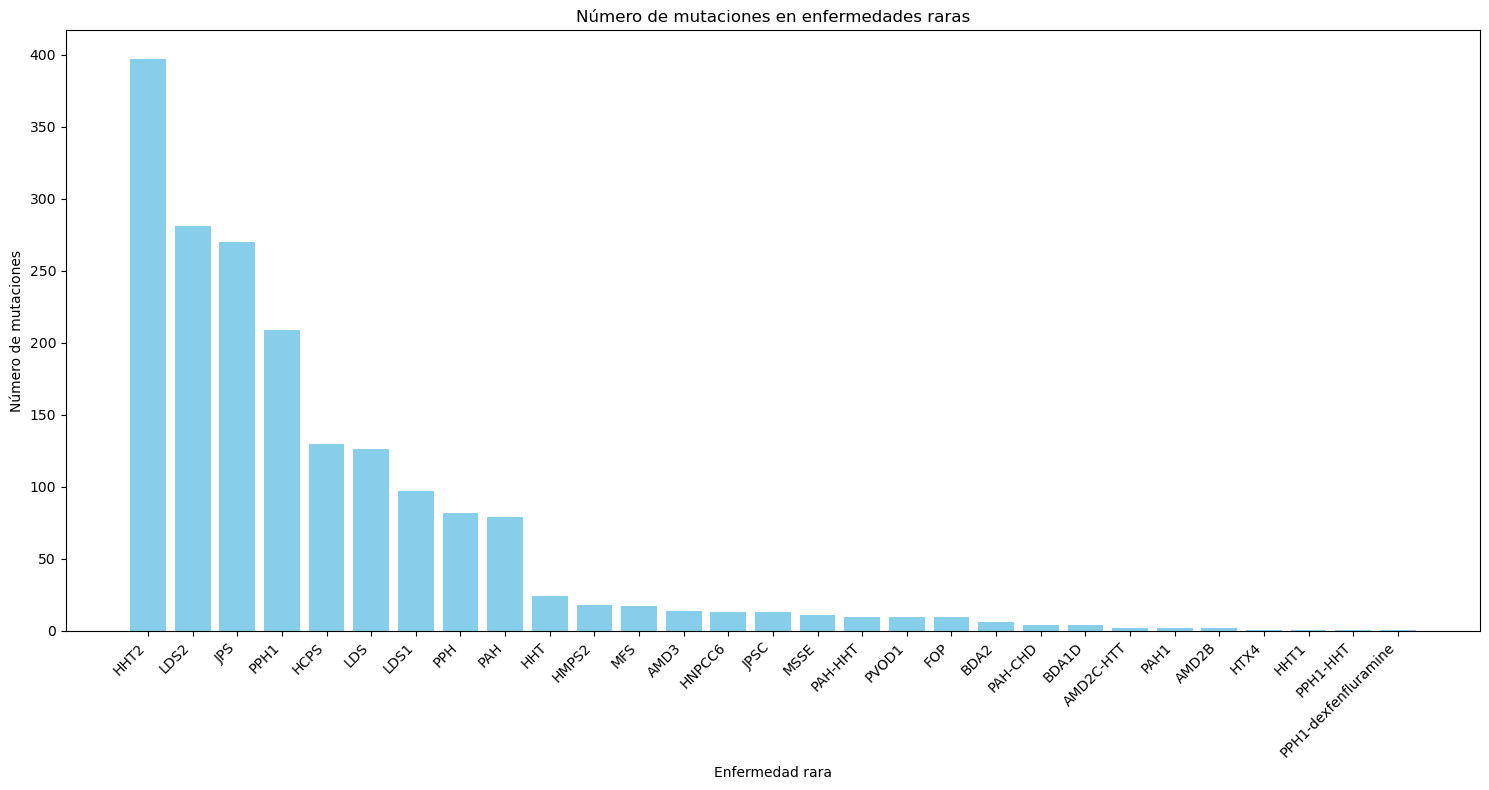

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# Agrupar y contar las mutaciones por 'Condition(s)' y contar las distintas mutaciones en 'Protein change'
mutation_counts = df.groupby(['Condition'])['Protein change'].nunique().reset_index(name='count')
mutation_counts = mutation_counts.sort_values(by='count', ascending=False)
mutation_counts.reset_index(drop=True, inplace=True)

# Configuración del gráfico
plt.figure(figsize=(15, 8))

# Crear el gráfico de barras
plt.bar(mutation_counts['Condition'], mutation_counts['count'], color='skyblue')

# Ajustar las etiquetas del eje x
plt.xticks(range(len(mutation_counts['Condition'])), mutation_counts['Condition'], rotation=45, ha="right", fontsize=10)

# Personalización del gráfico
plt.xlabel("Enfermedad rara")
plt.ylabel("Número de mutaciones")
plt.title("Número de mutaciones en enfermedades raras")

# Mostrar el gráfico sin la leyenda
plt.tight_layout()
plt.show()



In [18]:
df.shape

(1900, 7)

In [19]:
a = df[['GeneSymbol','Condition(s)', 'Condition', 'Protein change']]
a.drop_duplicates(['GeneSymbol','Condition(s)', 'Condition', 'Protein change'])

,GeneSymbol,Condition(s),Condition,Protein change
0,ACVR1,Progressive myositis ossificans,FOP,R258G
2,ACVR1,Progressive myositis ossificans,FOP,L196P
4,ACVR1,Progressive myositis ossificans,FOP,R202I
6,ACVR1,Progressive myositis ossificans,FOP,R375P
8,ACVR1,Progressive myositis ossificans,FOP,G328E
...,...,...,...,...
3600,TGFBR2,Loeys-Dietz syndrome 2,LDS2,L317P
3601,TGFBR2,Loeys-Dietz syndrome 2,LDS2,L344P
3602,TGFBR2,Loeys-Dietz syndrome 2,LDS2,L369P
3603,TGFBR2,"Colorectal cancer, hereditary nonpolyposis, ty...",HNPCC6,A535fs


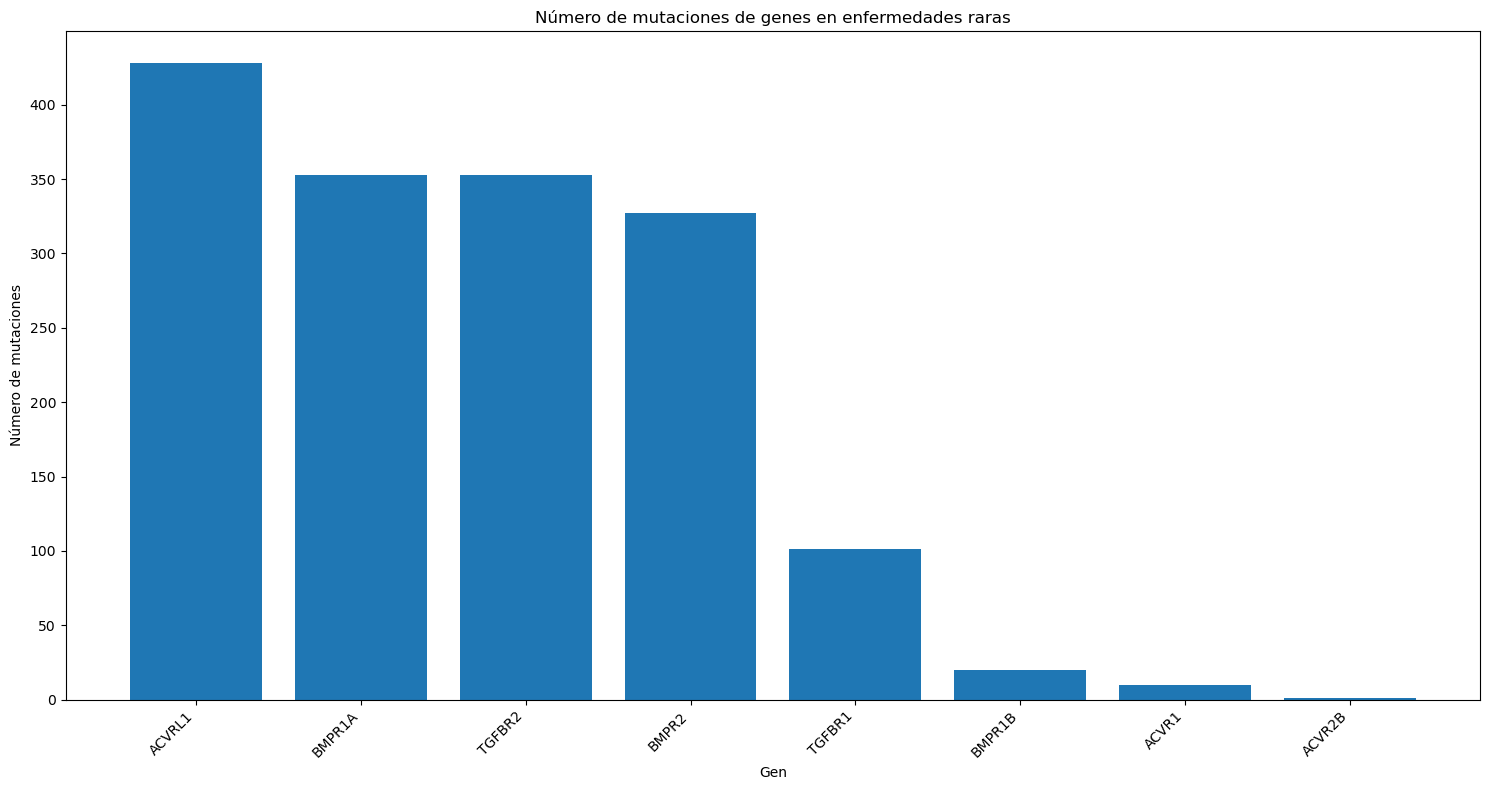

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# Agrupar y contar las mutaciones por 'Condition(s)' y contar las distintas mutaciones en 'Protein change'
mutation_counts = df.groupby(['GeneSymbol'])['Protein change'].nunique().reset_index(name='count')
mutation_counts = mutation_counts.sort_values(by='count', ascending=False)
mutation_counts.reset_index(drop=True, inplace=True)

# Configuración del gráfico
plt.figure(figsize=(15, 8))

# Crear el gráfico de barras
plt.bar(mutation_counts['GeneSymbol'], mutation_counts['count'], color='C0')

# Ajustar las etiquetas del eje x
plt.xticks(range(len(mutation_counts['GeneSymbol'])), mutation_counts['GeneSymbol'], rotation=45, ha="right", fontsize=10)

# Personalización del gráfico
plt.xlabel("Gen")
plt.ylabel("Número de mutaciones")
plt.title("Número de mutaciones de genes en enfermedades raras")

# Mostrar el gráfico sin la leyenda
plt.tight_layout()
plt.show()



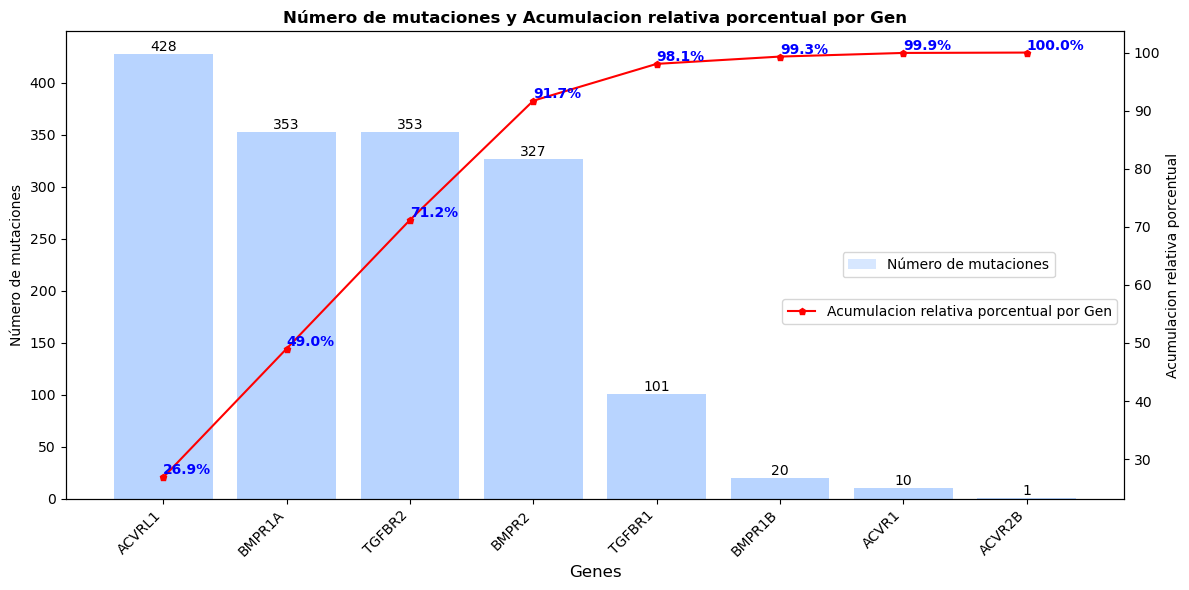

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Agrupar y contar las mutaciones por 'Condition(s)' y contar las distintas mutaciones en 'Protein change'
mutation_counts = df.groupby(['GeneSymbol'])['Protein change'].nunique().reset_index(name='mutation_count')
mutation_counts = mutation_counts.sort_values(by='mutation_count', ascending=False)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts['mutation_count'].cumsum() / mutation_counts['mutation_count'].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 6))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts['GeneSymbol'], mutation_counts["mutation_count"], color="#5599ff3b")

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts['GeneSymbol'], mutation_counts['mutation_count'], color="#5599ff3b", label='Número de mutaciones')

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color='red', marker="p", ms=5, label='Acumulacion relativa porcentual por Gen')

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=10)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color='blue', fontsize=10, weight='bold')

# Ajustar límites y etiquetas
ax.set_ylabel('Número de mutaciones')
ax2.set_ylabel('Acumulacion relativa porcentual')
ax.set_title('Número de mutaciones y Acumulacion relativa porcentual por Gen', weight='bold')
ax.set_xlabel('Genes', fontsize=12)


# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts['GeneSymbol'])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts['GeneSymbol'], rotation=45, ha="right")  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='center right', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='center right', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo



# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
family_name = 'STKR'
plt.savefig("../run/imagenes/barras_mutation_number_gen_RD_{0}.png".format(family_name), format='png', dpi=600)

plt.show()



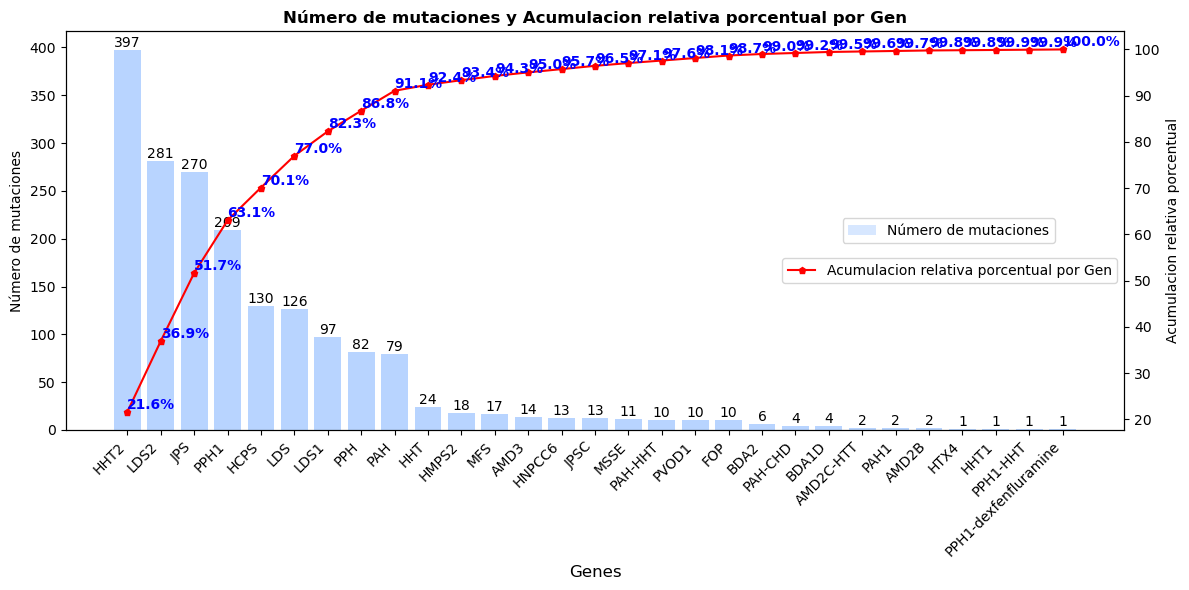

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Agrupar y contar las mutaciones por 'Condition(s)' y contar las distintas mutaciones en 'Protein change'
mutation_counts = df.groupby(['Condition'])['Protein change'].nunique().reset_index(name='mutation_count')
mutation_counts = mutation_counts.sort_values(by='mutation_count', ascending=False)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts['mutation_count'].cumsum() / mutation_counts['mutation_count'].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 6))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts['Condition'], mutation_counts["mutation_count"], color="#5599ff3b")

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts['Condition'], mutation_counts['mutation_count'], color="#5599ff3b", label='Número de mutaciones')

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color='red', marker="p", ms=5, label='Acumulacion relativa porcentual por Gen')

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=10)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color='blue', fontsize=10, weight='bold')

# Ajustar límites y etiquetas
ax.set_ylabel('Número de mutaciones')
ax2.set_ylabel('Acumulacion relativa porcentual')
ax.set_title('Número de mutaciones y Acumulacion relativa porcentual por Gen', weight='bold')
ax.set_xlabel('Genes', fontsize=12)


# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts['Condition'])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts['Condition'], rotation=45, ha="right")  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='center right', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='center right', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo



# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
family_name = 'STKR'
plt.savefig("../run/imagenes/barras_mutation_number_gen_RD_{0}.png".format(family_name), format='png', dpi=600)

plt.show()



In [23]:
df

,GeneSymbol,Condition(s),Protein change,Molecular consequence,VariationID,Germline classification,Condition
0,ACVR1,Progressive myositis ossificans,R258G,missense variant,216885,Likely pathogenic,FOP
2,ACVR1,Progressive myositis ossificans,L196P,missense variant,208843,Pathogenic,FOP
4,ACVR1,Progressive myositis ossificans,R202I,missense variant,29597,Pathogenic,FOP
6,ACVR1,Progressive myositis ossificans,R375P,missense variant,29596,Pathogenic,FOP
8,ACVR1,Progressive myositis ossificans,G328E,missense variant,29595,Pathogenic/Likely pathogenic,FOP
...,...,...,...,...,...,...,...
3600,TGFBR2,Loeys-Dietz syndrome 2,L317P,missense variant,12505,Pathogenic,LDS2
3601,TGFBR2,Loeys-Dietz syndrome 2,L344P,missense variant,12505,Pathogenic,LDS2
3602,TGFBR2,Loeys-Dietz syndrome 2,L369P,missense variant,12505,Pathogenic,LDS2
3603,TGFBR2,"Colorectal cancer, hereditary nonpolyposis, ty...",A535fs,frameshift variant,12501,Pathogenic,HNPCC6


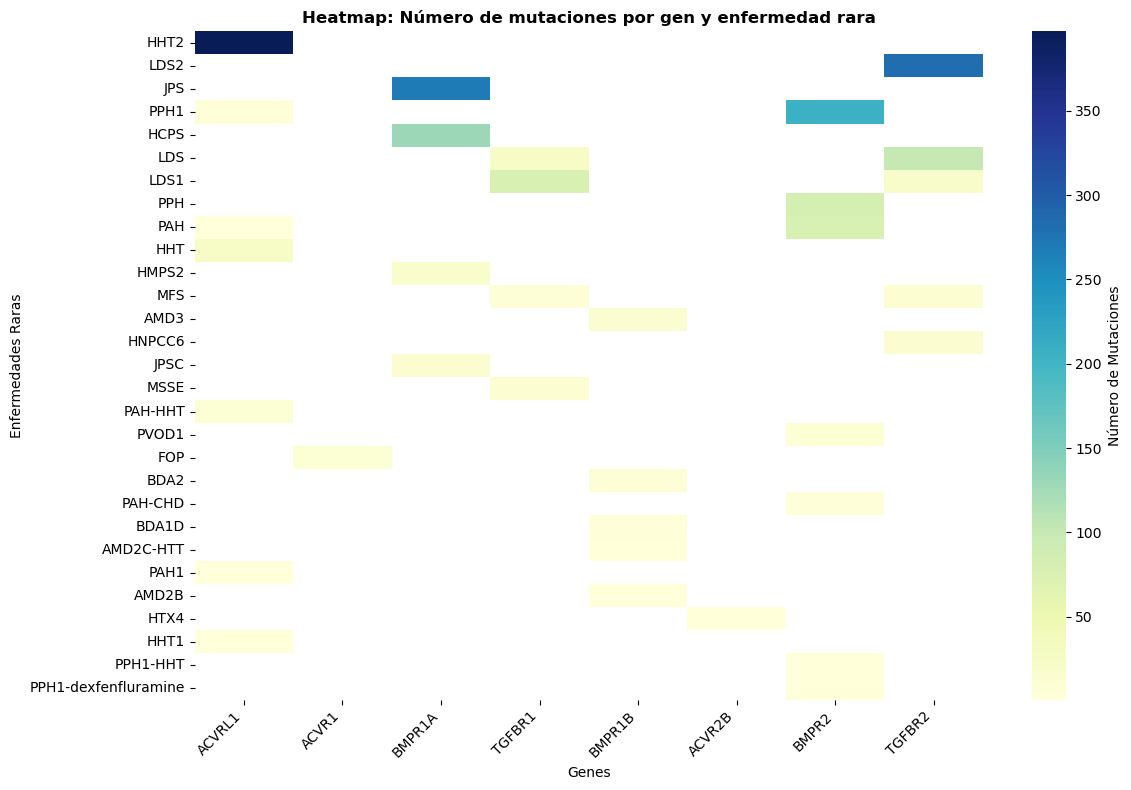

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Agrupar y contar las mutaciones por 'Condition(s)' y contar las distintas mutaciones en 'Protein change'
mutation_counts = df.groupby(['GeneSymbol', 'Condition'])['Protein change'].nunique().reset_index(name='count')
mutation_counts = mutation_counts.sort_values(by='count', ascending=False)
mutation_counts.reset_index(drop=True, inplace=True)

# Asegúrate de que los genes y tipos de cáncer estén ordenados por la suma de mutaciones
#ordered_genes = mutation_counts.groupby('GeneSymbol')['count'].sum().sort_values(ascending=False).index
ordered_genes = ['ACVRL1', 'ACVR1', 'BMPR1A','TGFBR1', 'BMPR1B',  'ACVR2B','BMPR2', 'TGFBR2']
ordered_cancer = mutation_counts.groupby('Condition')['count'].sum().sort_values(ascending=False).index

# Pivotear el DataFrame para que quede en formato adecuado para el heatmap
heatmap_data = mutation_counts.pivot_table(
    columns='GeneSymbol',
    index='Condition',
    values='count',
    aggfunc='sum'  # Asegúrate de que se agregue la frecuencia por gen y tipo de cáncer
).reindex(columns=ordered_genes, index=ordered_cancer)

# Crear el heatmap usando seaborn
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap="YlGnBu", annot=False, fmt=".0f", cbar_kws={'label': 'Número de Mutaciones'})


# Ajustar las etiquetas  para que estén horizontales
plt.gca().set_yticklabels(plt.gca().get_yticklabels(), rotation=0)
plt.gca().set_xticklabels(plt.gca().get_xticklabels(), rotation=45, ha='right')  # Rotar las etiquetas y alinearlas a la derecha

# Añadir título y etiquetas
plt.title("Heatmap: Número de mutaciones por gen y enfermedad rara", weight='bold')
plt.ylabel("Enfermedades Raras")
plt.xlabel("Genes")

# Ajustar automáticamente el diseño para evitar texto cortado
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../run/imagenes/heatmap_mutation_number_RD_{0}.png".format(family_name), format='png', dpi=600)

# Mostrar el gráfico
plt.show()


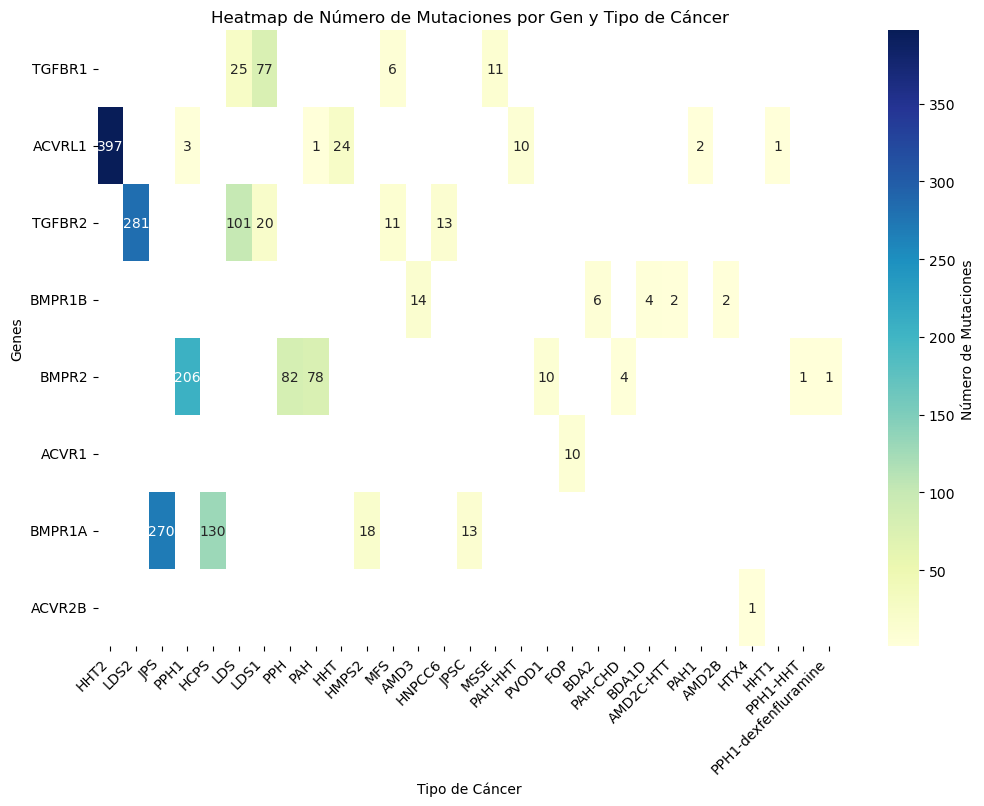

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Agrupar y contar las mutaciones por 'Condition(s)' y contar las distintas mutaciones en 'Protein change'
mutation_counts = df.groupby(['GeneSymbol', 'Condition'])['Protein change'].nunique().reset_index(name='count')
mutation_counts = mutation_counts.sort_values(by='count', ascending=False)
mutation_counts.reset_index(drop=True, inplace=True)

# Asegúrate de que los genes y tipos de cáncer estén ordenados por la suma de mutaciones
#ordered_genes = mutation_counts.groupby('GeneSymbol')['count'].sum().sort_values(ascending=False).index
ordered_genes = ['TGFBR1', 'ACVRL1', 'TGFBR2', 'BMPR1B',
       'BMPR2', 'ACVR1', 'BMPR1A', 'ACVR2B']
ordered_cancer = mutation_counts.groupby('Condition')['count'].sum().sort_values(ascending=False).index

# Pivotear el DataFrame para que quede en formato adecuado para el heatmap
heatmap_data = mutation_counts.pivot_table(
    index='GeneSymbol',
    columns='Condition',
    values='count',
    aggfunc='sum'  # Asegúrate de que se agregue la frecuencia por gen y tipo de cáncer
).reindex(index=ordered_genes, columns=ordered_cancer)

# Crear el heatmap usando seaborn
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap="YlGnBu", annot=True, fmt=".0f", cbar_kws={'label': 'Número de Mutaciones'})


# Ajustar las etiquetas  para que estén horizontales
plt.gca().set_yticklabels(plt.gca().get_yticklabels(), rotation=0)
plt.gca().set_xticklabels(plt.gca().get_xticklabels(), rotation=45, ha='right')  # Rotar las etiquetas y alinearlas a la derecha

# Añadir título y etiquetas
plt.title("Heatmap de Número de Mutaciones por Gen y Tipo de Cáncer")
plt.xlabel("Tipo de Cáncer")
plt.ylabel("Genes")

# Guardar el gráfico en formato SVG antes de mostrarlo
#plt.savefig("../run/imagenes/heatmap_mutation_number_{0}.svg".format(family_name), format='svg')

# Mostrar el gráfico
plt.show()


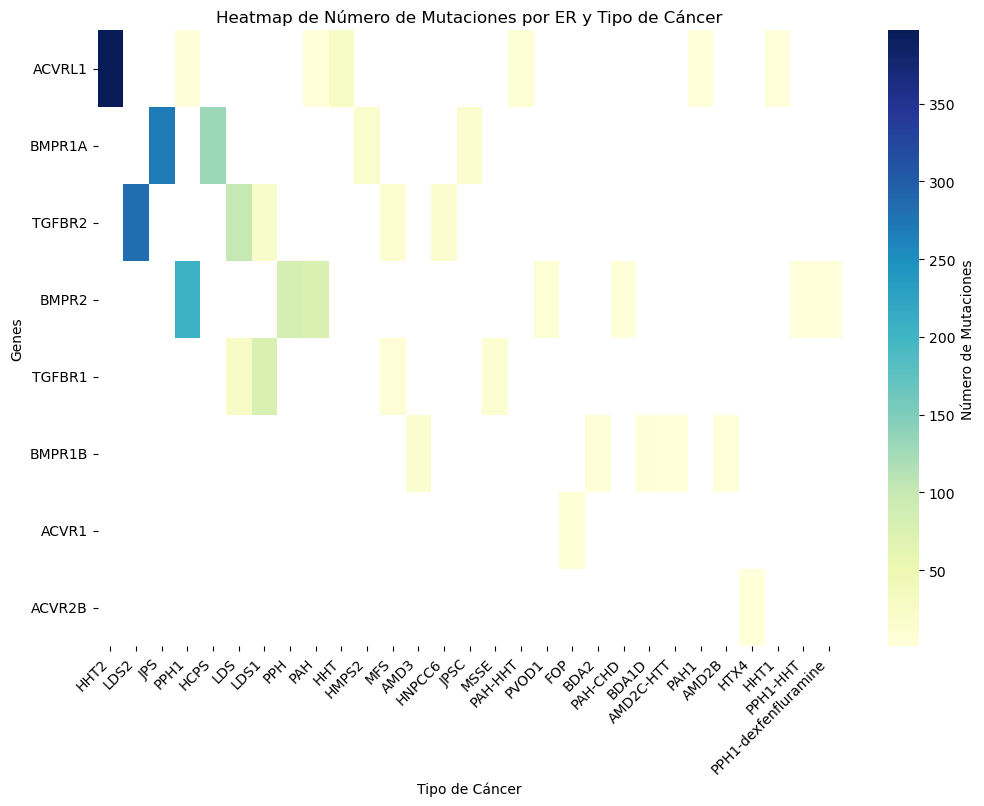

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Agrupar y contar las mutaciones por 'Condition(s)' y contar las distintas mutaciones en 'Protein change'
mutation_counts = df.groupby(['GeneSymbol', 'Condition'])['Protein change'].nunique().reset_index(name='count')
mutation_counts = mutation_counts.sort_values(by='count', ascending=False)
mutation_counts.reset_index(drop=True, inplace=True)

# Asegúrate de que los genes y tipos de cáncer estén ordenados por la suma de mutaciones
ordered_genes = mutation_counts.groupby('GeneSymbol')['count'].sum().sort_values(ascending=False).index
#ordered_genes = ['TGFBR1', 'ACVR1B', 'ACVR1C', 'ACVRL1', 'TGFBR2', 'ACVR2A', 'BMPR1B',
  #     'BMPR2', 'AMHR2', 'ACVR1', 'BMPR1A', 'ACVR2B']
ordered_cancer = mutation_counts.groupby('Condition')['count'].sum().sort_values(ascending=False).index

# Pivotear el DataFrame para que quede en formato adecuado para el heatmap
heatmap_data = mutation_counts.pivot_table(
    index='GeneSymbol',
    columns='Condition',
    values='count',
    aggfunc='sum'  # Asegúrate de que se agregue la frecuencia por gen y tipo de cáncer
).reindex(index=ordered_genes, columns=ordered_cancer)

# Crear el heatmap usando seaborn
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap="YlGnBu", annot=False, fmt=".0f", cbar_kws={'label': 'Número de Mutaciones'})


# Ajustar las etiquetas  para que estén horizontales
plt.gca().set_yticklabels(plt.gca().get_yticklabels(), rotation=0)
plt.gca().set_xticklabels(plt.gca().get_xticklabels(), rotation=45, ha='right')  # Rotar las etiquetas y alinearlas a la derecha

# Añadir título y etiquetas
plt.title("Heatmap de Número de Mutaciones por ER y Tipo de Cáncer")
plt.xlabel("Tipo de Cáncer")
plt.ylabel("Genes")

# Guardar el gráfico en formato SVG antes de mostrarlo
#plt.savefig("../run/imagenes/heatmap_mutation_number_{0}.svg".format(family_name), format='svg')

# Mostrar el gráfico
plt.show()

#LAS MUTACIONES SE REVISARON Y LAS MTACIONES QUE TIENEN IGUAL NUMERO NO SON IGUALES LAS MUTACIONES


In [27]:
df[df['Condition']=='AMD2B']

,GeneSymbol,Condition(s),Protein change,Molecular consequence,VariationID,Germline classification,Condition
1909,BMPR1B,Acromesomelic dysplasia 2B,R214S,missense variant,446284,Pathogenic,AMD2B
1914,BMPR1B,Acromesomelic dysplasia 2B,R244S,missense variant,446284,Pathogenic,AMD2B


In [28]:
df[df['Protein change']=='R361*']

,GeneSymbol,Condition(s),Protein change,Molecular consequence,VariationID,Germline classification,Condition
1768,BMPR1A,"Polyposis syndrome, hereditary mixed, 2",R361*,nonsense,183728,Pathogenic,HMPS2
1771,BMPR1A,Generalized juvenile polyposis/juvenile polypo...,R361*,nonsense,183728,Pathogenic,JPSC
1774,BMPR1A,Hereditary cancer-predisposing syndrome,R361*,nonsense,183728,Pathogenic,HCPS
1777,BMPR1A,Juvenile polyposis syndrome,R361*,nonsense,183728,Pathogenic,JPS


In [29]:
df[df['Condition']=='BMPR1B-RD']

,GeneSymbol,Condition(s),Protein change,Molecular consequence,VariationID,Germline classification,Condition


In [30]:
# Guardar los resultados en un archivo CSV
# Datos con la lista de genes quinasa a trabajar 
#interpro_code = 'IPR000333'
family_name = 'STKR'
df.to_csv('../data/mutaciones/rare_disease_variations_{0}.csv'.format(family_name), index=False)

Dominio

In [35]:
# Diccionario con los rangos de dominios por gen
gene_domain_ranges = {
    'ACVR1':  {'GS': (178, 208), 'Kinasa': (209, 502), 'Activina': (33, 102)},
    'ACVR1B': {'GS': (177, 207), 'Kinasa': (208, 497), 'Activina': (33, 104)},
    'ACVR1C': {'GS': (165, 195), 'Kinasa': (196, 485), 'Activina': (26, 95)},
    'ACVR2A': {'Kinasa': (192, 485), 'Activina': (55, 113)},
    'ACVR2B': {'Kinasa': (194, 484), 'Activina': (53, 111)},
    'ACVRL1': {'GS': (172, 202), 'Kinasa': (203, 493)},
    'AMHR2':  {'Kinasa': (203, 518)},
    'BMPR1A': {'GS': (204, 234), 'Kinasa': (235, 525), 'Activina': (59, 132)},
    'BMPR1B': {'GS': (174, 204), 'Kinasa': (205, 502), 'Activina': (30, 105)},
    'BMPR2':  {'Kinasa': (203, 504), 'Activina': (52, 126)},
    'TGFBR1': {'GS': (175, 205), 'Kinasa': (206, 495), 'Activina': (34, 109)},
    'TGFBR2': {'Kinasa': (244, 544), 'Activina': (49, 157)},    
}

# Función para determinar el dominio según el gen y la posición
def assign_domain(row):
    gene = row['GeneSymbol']
    mutation = row['Protein change']
    if gene in gene_domain_ranges:
        position = int(''.join(filter(str.isdigit, mutation)))  # Extraer el número de la mutación
        for domain, (start, end) in gene_domain_ranges[gene].items():
            if start <= position <= end:
                return domain
    return 'Otro'  # Asignar 'Otro' si no está en ningún rango

# Aplicar la función al DataFrame
df['Dominio'] = df.apply(assign_domain, axis=1)

# Verificar el resultado
df

/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_8354/838829444.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Dominio'] = df.apply(assign_domain, axis=1)


,GeneSymbol,Condition(s),Protein change,Molecular consequence,VariationID,Germline classification,Condition,Dominio
0,ACVR1,Progressive myositis ossificans,R258G,Cambio de sentido,216885,Likely pathogenic,FOP,Kinasa
2,ACVR1,Progressive myositis ossificans,L196P,Cambio de sentido,208843,Pathogenic,FOP,GS
4,ACVR1,Progressive myositis ossificans,R202I,Cambio de sentido,29597,Pathogenic,FOP,GS
6,ACVR1,Progressive myositis ossificans,R375P,Cambio de sentido,29596,Pathogenic,FOP,Kinasa
8,ACVR1,Progressive myositis ossificans,G328E,Cambio de sentido,29595,Pathogenic/Likely pathogenic,FOP,Kinasa
...,...,...,...,...,...,...,...,...
3600,TGFBR2,Loeys-Dietz syndrome 2,L317P,Cambio de sentido,12505,Pathogenic,LDS2,Kinasa
3601,TGFBR2,Loeys-Dietz syndrome 2,L344P,Cambio de sentido,12505,Pathogenic,LDS2,Kinasa
3602,TGFBR2,Loeys-Dietz syndrome 2,L369P,Cambio de sentido,12505,Pathogenic,LDS2,Kinasa
3603,TGFBR2,"Colorectal cancer, hereditary nonpolyposis, ty...",A535fs,Desplazamiento del marco,12501,Pathogenic,HNPCC6,Kinasa


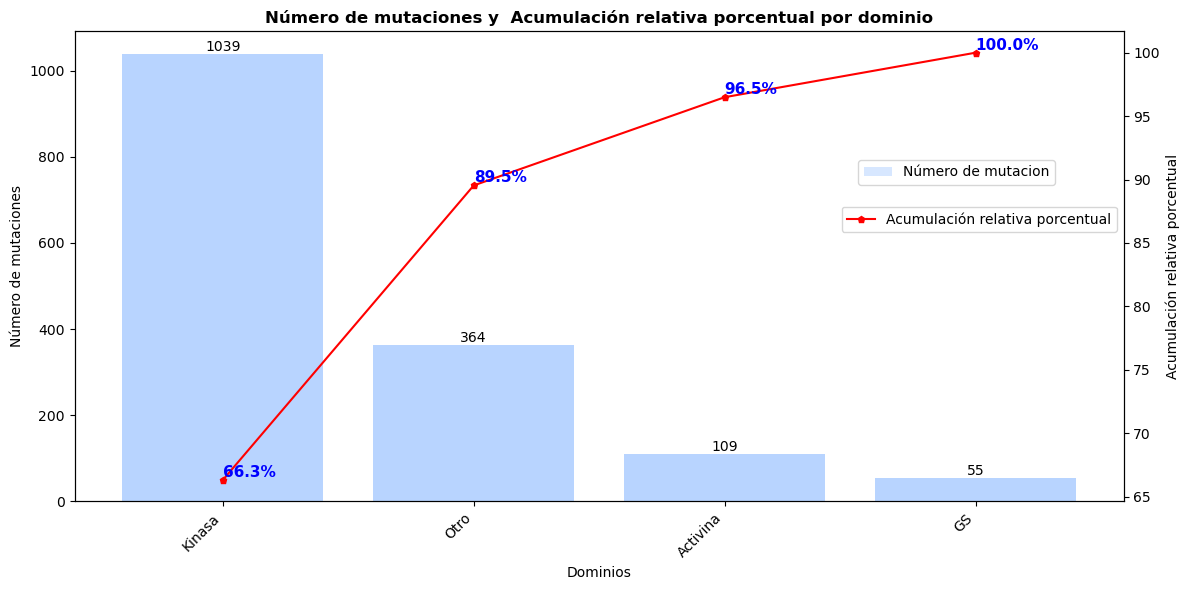

In [50]:
import pandas as pd
import matplotlib.pyplot as plt

# Agrupar y contar las mutaciones por 'Condition(s)' y contar las distintas mutaciones en 'Protein change'
mutation_counts = df.groupby(['Dominio'])['Protein change'].nunique().reset_index(name='mutation_count')
mutation_counts = mutation_counts.sort_values(by='mutation_count', ascending=False)
mutation_counts.reset_index(drop=True, inplace=True)

# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by='mutation_count', ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts['mutation_count'].cumsum() / mutation_counts['mutation_count'].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 6))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts['Dominio'], mutation_counts["mutation_count"], color="#5599ff3b")

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts['Dominio'], mutation_counts['mutation_count'], color="#5599ff3b", label='Número de mutacion')

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color="red", marker="p", ms=5, label='Acumulación relativa porcentual')

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=10)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color='blue', fontsize=11,fontweight  = 'bold')
# Ajustar límites y etiquetas
ax.set_ylabel('Número de mutaciones')
ax2.set_ylabel('Acumulación relativa porcentual')
ax.set_title('Número de mutaciones y  Acumulación relativa porcentual por dominio', weight='bold')
ax.set_xlabel('Dominios')

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts['Dominio'])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts['Dominio'], rotation=45, ha="right")  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='center right', bbox_to_anchor=(0.941, 0.7))  # Leyenda del primer eje
ax2.legend(loc='center right', bbox_to_anchor=(1, 0.6))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../run/imagenes/barras_mutation_number_DOMINIO_{0}.png".format(family_name), format='png', dpi=600)

plt.show()



## Consequence mutacion

In [37]:
df.head(2)

,GeneSymbol,Condition(s),Protein change,Molecular consequence,VariationID,Germline classification,Condition,Dominio
0,ACVR1,Progressive myositis ossificans,R258G,Cambio de sentido,216885,Likely pathogenic,FOP,Kinasa
2,ACVR1,Progressive myositis ossificans,L196P,Cambio de sentido,208843,Pathogenic,FOP,GS


In [38]:
consecuencia = {'frameshift variant': 'Desplazamiento del marco', 'inframe_deletion':'Delecion sin desplazamiento', 'missense variant':'Cambio de sentido', 'nonsense':'Sin sentido'}
df['Molecular consequence'] = df['Molecular consequence'].map(consecuencia)

/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_8354/1782109574.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Molecular consequence'] = df['Molecular consequence'].map(consecuencia)


In [39]:
# Crear una lista única de condiciones de enfermedades raras en el DataFrame
lista_CQ = df['Molecular consequence'].unique()

# Crear un diccionario para almacenar un DataFrame por cada condición de enfermedad rara
dict_rd = {}

# Iterar sobre cada condición en lista_rd
for tipo in lista_CQ:
    # Filtrar el DataFrame original para obtener solo las filas correspondientes a la condición actual
    df_disease = df[df['Molecular consequence'] == tipo]
    
    # Asignar el DataFrame filtrado al diccionario con la clave correspondiente a la condición
    dict_rd[tipo] = df_disease

# Iterar sobre el diccionario ordenado por el número de mutaciones únicas en 'Protein change', en orden descendente
for i, (Disease, data) in enumerate(sorted(dict_rd.items(), key=lambda x: len(x[1]['Protein change'].unique()), reverse=True)):
    print(f"{i+1}. Número de mutaciones en enfermedades raras {Disease}: {len(data['Protein change'].unique())}")


1. Número de mutaciones en enfermedades raras nan: 0


In [40]:
df_consequence = df[['Protein change','Molecular consequence']]

# Paso 1: Eliminar duplicados por paciente y gen, pero considerando solo mutaciones únicas por gen y paciente
df_consequence = df_consequence.drop_duplicates(subset=['Protein change','Molecular consequence'])

# Paso 2: Contar la frecuencia de mutación por gen (mutaciones únicas por paciente)
mutation_frequencies_consequence = df_consequence.groupby(['Molecular consequence']).size().reset_index(name='mutation_count')

# Paso 3: Contar el número total de pacientes
total_mutation = df['Protein change'].nunique()

# Paso 4: Calcular la frecuencia de mutación como la proporción de mutaciones por gen al número total de pacientes
mutation_frequencies_consequence['mutation_frequency'] = (mutation_frequencies_consequence['mutation_count'] / total_mutation)*100

# Paso 5: Mostrar los resultados
mutation_frequencies_consequence.sort_values(ascending=False, by='mutation_count')


,Molecular consequence,mutation_count,mutation_frequency


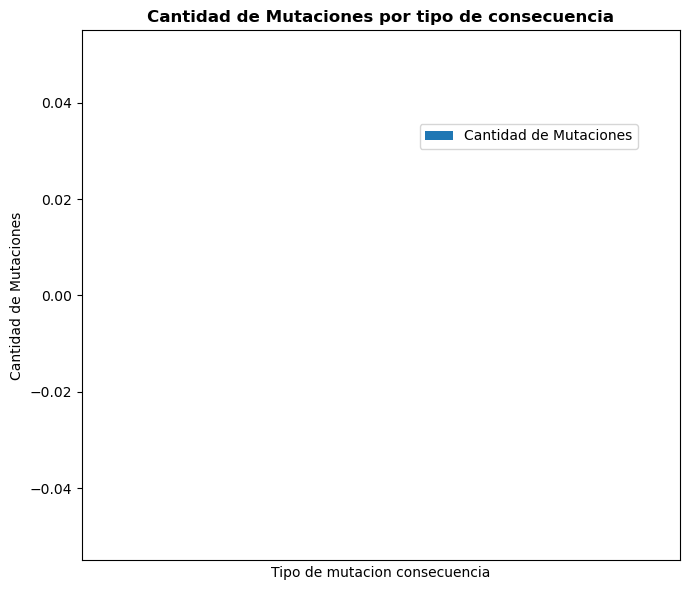

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
# Agrupar por consequence_type y contar el número de mutaciones únicas
mutation_counts = df.groupby('Molecular consequence')['Protein change'].nunique().reset_index(name='num_mutaciones')

# Ordenar por el número de mutaciones de forma descendente
mutation_counts = mutation_counts.sort_values(by='num_mutaciones', ascending=False)

# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by='num_mutaciones', ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)


# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(7, 6))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts['Molecular consequence'], mutation_counts["num_mutaciones"], color="#5599ff3b")

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts['Molecular consequence'], mutation_counts['num_mutaciones'], color="#5599ff3b",label='Cantidad de Mutaciones')

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=8)


# Ajustar límites y etiquetas
ax.set_ylabel('Cantidad de Mutaciones', fontsize=10)
ax.set_xlabel('Tipo de mutacion consecuencia', fontsize=10)

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts['Molecular consequence'])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts['Molecular consequence'], rotation=45, ha="right")  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.set_title('Cantidad de Mutaciones por tipo de consecuencia', weight='bold')
ax.legend(loc='center right', bbox_to_anchor=(0.941, 0.8))  # Leyenda del primer eje
ax2.legend(loc='center right', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo



# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../run/imagenes/barras_mutation_RD_CONSEQUENCE_{0}.svg".format(family_name), format='svg')

plt.show()

## Genes en mas de una RD

In [42]:
df

,GeneSymbol,Condition(s),Protein change,Molecular consequence,VariationID,Germline classification,Condition,Dominio
0,ACVR1,Progressive myositis ossificans,R258G,NaN,216885,Likely pathogenic,FOP,Kinasa
2,ACVR1,Progressive myositis ossificans,L196P,NaN,208843,Pathogenic,FOP,GS
4,ACVR1,Progressive myositis ossificans,R202I,NaN,29597,Pathogenic,FOP,GS
6,ACVR1,Progressive myositis ossificans,R375P,NaN,29596,Pathogenic,FOP,Kinasa
8,ACVR1,Progressive myositis ossificans,G328E,NaN,29595,Pathogenic/Likely pathogenic,FOP,Kinasa
...,...,...,...,...,...,...,...,...
3600,TGFBR2,Loeys-Dietz syndrome 2,L317P,NaN,12505,Pathogenic,LDS2,Kinasa
3601,TGFBR2,Loeys-Dietz syndrome 2,L344P,NaN,12505,Pathogenic,LDS2,Kinasa
3602,TGFBR2,Loeys-Dietz syndrome 2,L369P,NaN,12505,Pathogenic,LDS2,Kinasa
3603,TGFBR2,"Colorectal cancer, hereditary nonpolyposis, ty...",A535fs,NaN,12501,Pathogenic,HNPCC6,Kinasa


In [43]:
import pandas as pd

# Supongamos que este es tu DataFrame original


# Agrupar por gen y mutación, y contar los tipos de cáncer únicos
rd_counts = df.groupby(['GeneSymbol', 'Protein change'])['Condition'].unique().reset_index()

# Contar la cantidad de tipos de cáncer
rd_counts['cantidad_rd'] = rd_counts['Condition'].apply(lambda x: len(x))

# Renombrar la columna de tipos de cáncer involucrados
rd_counts.columns = ['GeneSymbol', 'Protein change','rd_involucradas', 'cantidad_rd']

# Crear la nueva columna 'cancer_invol'
rd_counts['rd_invol'] = rd_counts['cantidad_rd'].astype(str)



# Mostrar el DataFrame resultante
rd_counts.sort_values(by='cantidad_rd')


,GeneSymbol,Protein change,rd_involucradas,cantidad_rd,rd_invol
0,ACVR1,G328E,[FOP],1,1
1018,BMPR2,Q6fs,[PPH1],1,1
1017,BMPR2,Q657fs,[PPH1],1,1
1016,BMPR2,Q657*,[PPH1],1,1
1015,BMPR2,Q6*,[PPH1],1,1
...,...,...,...,...,...
600,BMPR1A,L317fs,"[HMPS2, JPS, HCPS]",3,3
1230,TGFBR1,R491W,"[LDS1, MSSE, LDS]",3,3
688,BMPR1A,R361*,"[HMPS2, JPSC, HCPS, JPS]",4,4
806,BMPR1B,R214S,"[BDA1D, AMD3, AMD2B, BDA2]",4,4


In [44]:
# Filtrar las mutaciones que ocurren en más de un tipo de cáncer
repeated_mutations = rd_counts[rd_counts['cantidad_rd'] > 2 ]
print(len(repeated_mutations))
print(repeated_mutations['GeneSymbol'].unique())
# Agrupar por 'GeneSymbol' y listar las mutaciones en cada gen
mutaciones_por_gen = repeated_mutations.groupby('GeneSymbol')['Protein change'].apply(list)

# Mostrar el número total de genes y las mutaciones asociadas a cada uno
print(f"Número de genes con mutaciones repetidas: {len(mutaciones_por_gen)}\n")
for gen, mutaciones in mutaciones_por_gen.items():
    print(f"Gen: {gen}\n'{gen}': {mutaciones}\n")



32
['BMPR1A' 'BMPR1B' 'BMPR2' 'TGFBR1' 'TGFBR2']
Número de genes con mutaciones repetidas: 5

Gen: BMPR1A
'BMPR1A': ['L15fs', 'L317fs', 'L59*', 'R228*', 'R361*', 'R9*', 'Y407*']

Gen: BMPR1B
'BMPR1B': ['R214S', 'R244S']

Gen: BMPR2
'BMPR2': ['L287*', 'R147*', 'R211*', 'R899*', 'W414*', 'W466*']

Gen: TGFBR1
'TGFBR1': ['R410W', 'R487W', 'R491W', 'S164L', 'S241L', 'S245L']

Gen: TGFBR2
'TGFBR2': ['R205*', 'R375*', 'R400*', 'R460*', 'R494*', 'R495*', 'R496*', 'R504*', 'R520*', 'R531*', 'R556*']



In [45]:
repeated_mutations

,GeneSymbol,Protein change,rd_involucradas,cantidad_rd,rd_invol
586,BMPR1A,L15fs,"[JPSC, HCPS, JPS]",3,3
600,BMPR1A,L317fs,"[HMPS2, JPS, HCPS]",3,3
613,BMPR1A,L59*,"[HCPS, JPS, JPSC]",3,3
683,BMPR1A,R228*,"[HCPS, JPS, JPSC]",3,3
688,BMPR1A,R361*,"[HMPS2, JPSC, HCPS, JPS]",4,4
703,BMPR1A,R9*,"[HCPS, HMPS2, JPS]",3,3
782,BMPR1A,Y407*,"[JPS, HCPS, JPSC]",3,3
806,BMPR1B,R214S,"[BDA1D, AMD3, AMD2B, BDA2]",4,4
807,BMPR1B,R244S,"[BDA1D, AMD3, AMD2B, BDA2]",4,4
962,BMPR2,L287*,"[PPH, PPH1, PAH]",3,3


In [46]:
df[df['Protein change']=='R361*']

,GeneSymbol,Condition(s),Protein change,Molecular consequence,VariationID,Germline classification,Condition,Dominio
1768,BMPR1A,"Polyposis syndrome, hereditary mixed, 2",R361*,NaN,183728,Pathogenic,HMPS2,Kinasa
1771,BMPR1A,Generalized juvenile polyposis/juvenile polypo...,R361*,NaN,183728,Pathogenic,JPSC,Kinasa
1774,BMPR1A,Hereditary cancer-predisposing syndrome,R361*,NaN,183728,Pathogenic,HCPS,Kinasa
1777,BMPR1A,Juvenile polyposis syndrome,R361*,NaN,183728,Pathogenic,JPS,Kinasa


In [47]:
tabla = repeated_mutations.groupby(['GeneSymbol','rd_involucradas']).size().reset_index(name='Count')
#tabla.to_excel('mutaciones_agrupadas_rd.xlsx', index=False)
tabla.sort_values(by='GeneSymbol', ascending=False)

TypeError: unhashable type: 'numpy.ndarray'

In [ ]:
# Convertir las listas de 'tipos_cancer_involucrados' a una cadena de texto sin corchetes y comillas
repeated_mutations['rd_involucradas'] = repeated_mutations['rd_involucradas'].apply(lambda x: ', '.join(x))
repeated_mutations

In [48]:
rd_counts

,GeneSymbol,Protein change,rd_involucradas,cantidad_rd,rd_invol
0,ACVR1,G328E,[FOP],1,1
1,ACVR1,G328R,[FOP],1,1
2,ACVR1,G328W,[FOP],1,1
3,ACVR1,G356D,[FOP],1,1
4,ACVR1,L196P,[FOP],1,1
...,...,...,...,...,...
1588,TGFBR2,Y471D,[LDS2],1,1
1589,TGFBR2,Y479D,[LDS2],1,1
1590,TGFBR2,Y495D,[LDS2],1,1
1591,TGFBR2,Y506D,[LDS2],1,1


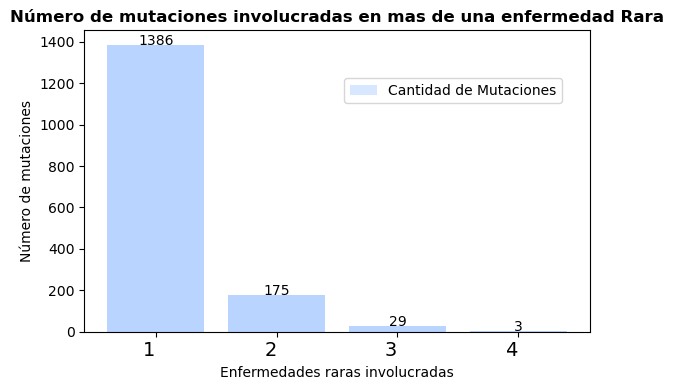

In [49]:
import pandas as pd
import matplotlib.pyplot as plt

# Supongamos que df ya está definido y contiene las columnas necesarias

# Contar el número de mutaciones (aa_mutation) por tipo de cáncer involucrado
mutation_counts = rd_counts.groupby(['rd_invol'], as_index=False)['Protein change'].count()
mutation_counts.rename(columns={'Protein change': 'numero_mutaciones'}, inplace=True)

# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by='numero_mutaciones', ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts['numero_mutaciones'].cumsum() / mutation_counts['numero_mutaciones'].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(6,4))

# Gráfico de barras para el número de mutaciones por tipo de cáncer
bars = ax.bar(mutation_counts['rd_invol'], mutation_counts['numero_mutaciones'], color="#5599ff3b")

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts['rd_invol'], mutation_counts['numero_mutaciones'], color="#5599ff3b",label='Cantidad de Mutaciones')

# Crear un segundo eje y para la línea de acumulación relativa porcentual
#ax2 = ax.twinx()
#ax2.plot(mutation_counts['cancer_invol'], mutation_counts['relativa_acum_porcentual'], color='C1', marker='o', ms=5, label='Frecuencia Relativa Acumulada')

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{height}', ha='center', va='baseline', color='black', fontsize=10)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
#for i, value in enumerate(mutation_counts['relativa_acum_porcentual']):
   # ax2.text(i, value, f'{value:.1f}%', ha='left', va='top', color='red')

# Ajustar límites y etiquetas
ax.set_ylabel('Número de mutaciones')
ax2.set_ylabel('Accumulated Relative Frequency (%)')
ax.set_title('Número de mutaciones involucradas en mas de una enfermedad Rara', weight='bold')
plt.xlabel('Enfermedades raras involucradas')

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts['rd_invol'])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts['rd_invol'], rotation=0, ha='right', fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='center left', bbox_to_anchor=(0.5, 0.8))  # Leyenda del primer eje
ax2.legend(loc='center left', bbox_to_anchor=(0.1, 0.4))  # Leyenda del segundo eje, un poco más abajo



# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
family_name = 'STKR'
plt.savefig("../run/imagenes/RD_invol_{0}.png".format(family_name), format='png', dpi=600)

# Mostrar el gráfico
plt.show()